# 06 · ¿El pop es un género o una etiqueta residual?

Parte de la pregunta P3. En todos los modelos el pop es la clase con menor F1 (0,38 con TF-IDF) y la que más se confunde con rock y R&B. Hay dos explicaciones posibles: que el pop sea un género con lenguaje propio pero con etiquetas ruidosas, o que funcione como etiqueta **residual**, que agrupa lo que no encaja en los demás géneros.

Se abordan desde dos miradas complementarias, sin etiquetas:

- **Temas, género por género** (este notebook, secciones 1–4): tópicos LDA y distancia de Jensen-Shannon entre la distribución media de tópicos de cada género y la del resto.
- **Significado, canción por canción** (sección siguiente, sobre embeddings): agrupamiento no supervisado y pureza de vecinos.

Si las dos miradas coinciden, la conclusión es robusta; si discrepan, la discrepancia es en sí un resultado.

**Predicción escrita antes de correr.** Si el pop es residual, su distribución media de tópicos debería ser la más cercana al resto de los géneros, para cualquier cantidad de tópicos, porque se parecería a una mezcla de los demás. Si es un género con lenguaje propio, no tiene por qué ser el más cercano.

Requisito: `data/processed/muestra.parquet` (`python -m src.muestra`). Tarda unos 10 minutos en CPU, casi todo en ajustar los tres modelos LDA.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import jensenshannon
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.datos import GENEROS, SEMILLA
from src.evaluacion import K, etiquetas

PROC = RAIZ / "data" / "processed"
FIG = RAIZ / "reports" / "figures"
TAB = RAIZ / "reports" / "tablas"

pd.set_option("display.width", 180)
pd.set_option("display.float_format", "{:,.3f}".format)
NOMBRE = {"pop": "Pop", "rap": "Rap", "rock": "Rock", "rb": "R&B", "country": "Country"}
COLOR = {"pop": "#2a78d6", "rap": "#eb6834", "rock": "#1baf7a", "rb": "#eda100", "country": "#e87ba4"}
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 9, "axes.titlesize": 9.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2,
    "ytick.color": TINTA_2, "text.color": TINTA, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "font.family": "Arial",
})


def guardar(fig, nombre):
    fig.savefig(FIG / f"{nombre}.png", bbox_inches="tight", facecolor="white")


muestra = pd.read_parquet(PROC / "muestra.parquet", columns=["id", "tag", "artist", "letra"])
Y = etiquetas(muestra["tag"])
codigo_artista, artistas_unicos = pd.factorize(muestra["artist"])
print(f"{len(muestra):,} canciones de {len(artistas_unicos):,} artistas")

50,000 canciones de 33,401 artistas


## 1. Tópicos LDA

Bolsa de palabras con las palabras de al menos tres letras, sin las palabras funcionales del inglés, presentes en al menos 20 letras y en no más de la mitad (hasta 20.000 palabras). LDA con aprendizaje en línea (15 iteraciones, semilla 42) para K = 8, 12 y 20 tópicos. El modelo se ajusta sobre todas las letras **sin usar el género**: es una descripción del corpus, no un clasificador, así que no hace falta particionar.

In [2]:
K_TOPICOS = [8, 12, 20]
K_PRINCIPAL = 12

vectorizador = CountVectorizer(stop_words="english", lowercase=True, min_df=20, max_df=0.5, max_features=20_000,
                               token_pattern=r"(?u)\b[a-z][a-z']{2,}\b")
X = vectorizador.fit_transform(muestra["letra"])
vocabulario = np.array(vectorizador.get_feature_names_out())
print(f"matriz documento-palabra: {X.shape[0]:,} × {X.shape[1]:,}")

lda, theta = {}, {}
for k in K_TOPICOS:
    t0 = time.time()
    lda[k] = LatentDirichletAllocation(n_components=k, learning_method="online", max_iter=15, batch_size=2048,
                                       random_state=SEMILLA, n_jobs=-1)
    theta[k] = lda[k].fit_transform(X)
    print(f"K = {k:2d}: {time.time() - t0:.0f} s, perplejidad {lda[k].perplexity(X):,.0f}")

matriz documento-palabra: 50,000 × 11,618


K =  8: 269 s, perplejidad 1,462


K = 12: 268 s, perplejidad 1,448


K = 20: 267 s, perplejidad 1,429


## 2. Temas del modelo principal (K = 12)

Las ocho palabras de mayor peso en cada tópico y el peso medio de cada tópico en las letras de cada género.

In [3]:
temas = pd.DataFrame({
    "palabras principales": [", ".join(vocabulario[np.argsort(-c)[:8]]) for c in lda[K_PRINCIPAL].components_],
}, index=[f"T{i}" for i in range(K_PRINCIPAL)])
peso_genero = pd.DataFrame(theta[K_PRINCIPAL]).groupby(Y).mean()
peso_genero.index = [NOMBRE[GENEROS[i]] for i in peso_genero.index]
peso_genero.columns = temas.index
temas = temas.join(peso_genero.T.round(3))
temas.to_csv(TAB / "pop_lda_temas_k12.csv")
temas

,palabras principales,Pop,Rap,Rock,R&B,Country
T0,"you're, can't, it's, time, feel, think, say, i've",0.243,0.125,0.236,0.214,0.145
T1,"got, good, man, ain't, bad, she's, that's, said",0.054,0.072,0.046,0.051,0.112
T2,"fuck, shit, bitch, got, ain't, fucking, money,...",0.027,0.177,0.025,0.048,0.015
T3,"yeah, got, ain't, it's, aye, woah, gon, ayy",0.036,0.076,0.019,0.055,0.046
T4,"it's, people, world, new, mind, time, life, space",0.060,0.083,0.110,0.041,0.029
T5,"god, life, die, lord, blood, soul, dead, death",0.097,0.056,0.198,0.047,0.110
T6,"baby, gonna, come, got, hey, you're, girl, body",0.052,0.025,0.031,0.084,0.048
T7,"love, i'll, let, heart, ooh, away, hold, you're",0.124,0.025,0.080,0.117,0.115
T8,"yeah, wanna, want, it's, make, girl, need, gotta",0.090,0.081,0.047,0.171,0.051
T9,"night, we're, light, tonight, eyes, sun, feel,...",0.101,0.031,0.100,0.059,0.099


## 3. Distancia de cada género al resto

Para cada género se compara su distribución media de tópicos con el promedio de las de los otros cuatro géneros (cada uno pesa lo mismo), mediante la distancia de Jensen-Shannon. El IC 95% sale de 1.000 remuestreos de artistas, igual que las métricas de los modelos: las canciones de un mismo artista no son independientes. Además se informa en qué proporción de los remuestreos cada género es el más cercano al resto.

In [4]:
def medias_por_genero(t, w):
    """Distribución media de tópicos de cada género, con pesos por canción (K × tópicos)."""
    G = np.zeros((len(Y), K))
    G[np.arange(len(Y)), Y] = w
    return (G.T @ t) / G.sum(0)[:, None]


def distancia_al_resto(medias):
    return np.array([jensenshannon(medias[g], np.delete(medias, g, axis=0).mean(0)) for g in range(K)])


rng = np.random.default_rng(SEMILLA)
N_BOOT = 1000
pesos = [rng.multinomial(len(artistas_unicos), np.full(len(artistas_unicos), 1 / len(artistas_unicos)))[codigo_artista]
         for _ in range(N_BOOT)]   # los mismos remuestreos para todos los K

filas, boot = [], {}
for k in K_TOPICOS:
    punto = distancia_al_resto(medias_por_genero(theta[k], np.ones(len(Y))))
    boot[k] = np.array([distancia_al_resto(medias_por_genero(theta[k], w)) for w in pesos])
    lo, hi = np.percentile(boot[k], [2.5, 97.5], axis=0)
    mas_cercano = np.bincount(boot[k].argmin(1), minlength=K) / N_BOOT
    for g in range(K):
        filas.append({"K": k, "género": NOMBRE[GENEROS[g]], "JS al resto": punto[g], "IC inf": lo[g], "IC sup": hi[g],
                      "puesto (1 = más cercano)": int((punto < punto[g]).sum() + 1),
                      "% remuestreos en que es el más cercano": 100 * mas_cercano[g]})
distancias = pd.DataFrame(filas)
distancias.to_csv(TAB / "pop_lda_distancia_al_resto.csv", index=False)
distancias.pivot(index="género", columns="K", values="JS al resto").loc[[NOMBRE[g] for g in GENEROS]]

K,8,12,20
género,,,
Pop,0.137,0.127,0.132
Rap,0.363,0.348,0.341
Rock,0.231,0.227,0.217
R&B,0.189,0.185,0.167
Country,0.244,0.249,0.231


In [5]:
distancias.set_index(["K", "género"])[["IC inf", "IC sup", "puesto (1 = más cercano)",
                                        "% remuestreos en que es el más cercano"]]

IC inf  IC sup  puesto (1 = más cercano)  % remuestreos en que es el más cercano
K  género                                                                                   
8  Pop       0.133   0.142                         1                                 100.000
   Rap       0.359   0.368                         5                                   0.000
   Rock      0.226   0.236                         3                                   0.000
   R&B       0.184   0.194                         2                                   0.000
   Country   0.238   0.249                         4                                   0.000
12 Pop       0.122   0.132                         1                                 100.000
   Rap       0.344   0.352                         5                                   0.000
   Rock      0.223   0.232                         3                                   0.000
   R&B       0.180   0.190                         2                                   0.000
   Country   0.244   0.255                         4                                   0.000
20 Pop       0.128   0.137                         1                                 100.000
   Rap       0.337   0.345                         5                                   0.000
   Rock      0.213   0.222                         3                                   0.000
   R&B       0.162   0.172                         2                                   0.000
   Country   0.226   0.237                         4                                   0.000

## 4. Distancias entre pares de géneros (K = 12)

Si el pop es una mezcla de otros géneros, debería quedar cerca de aquellos con los que más se confunde el clasificador (rock y R&B).

In [6]:
medias_k = medias_por_genero(theta[K_PRINCIPAL], np.ones(len(Y)))
pares = pd.DataFrame([[jensenshannon(medias_k[a], medias_k[b]) for b in range(K)] for a in range(K)],
                     index=[NOMBRE[g] for g in GENEROS], columns=[NOMBRE[g] for g in GENEROS])
pares.to_csv(TAB / "pop_lda_distancias_pares_k12.csv")
mas_cercano = {g: pares.loc[g].drop(g).idxmin() for g in pares.index}
print("género más cercano a cada uno:", mas_cercano)
pares

género más cercano a cada uno: {'Pop': 'R&B', 'Rap': 'R&B', 'Rock': 'Pop', 'R&B': 'Pop', 'Country': 'Pop'}


,Pop,Rap,Rock,R&B,Country
Pop,0.000,0.352,0.152,0.151,0.188
Rap,0.352,0.000,0.393,0.306,0.421
Rock,0.152,0.393,0.000,0.281,0.223
R&B,0.151,0.306,0.281,0.000,0.277
Country,0.188,0.421,0.223,0.277,0.000


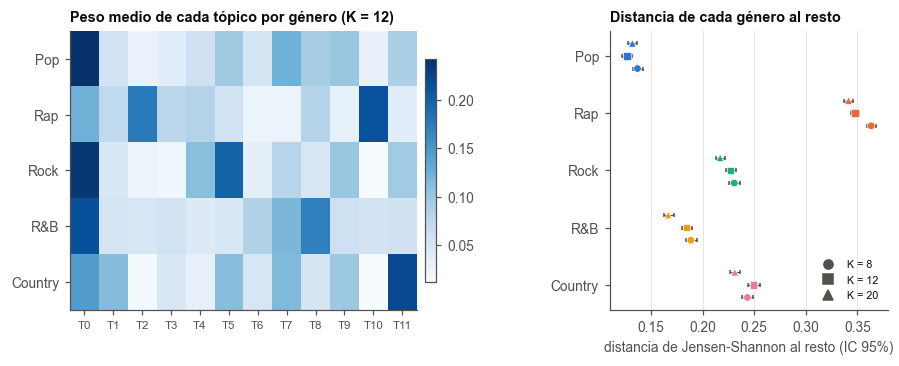

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.3), gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.35})
im = a1.imshow(peso_genero.values, cmap="Blues", aspect="auto")
a1.set_yticks(range(K), peso_genero.index)
a1.set_xticks(range(K_PRINCIPAL), temas.index, fontsize=7.5)
a1.grid(False)
a1.set_title(f"Peso medio de cada tópico por género (K = {K_PRINCIPAL})")
fig.colorbar(im, ax=a1, shrink=0.8, pad=0.02)

desplazamiento = {8: -0.22, 12: 0, 20: 0.22}
marcador = {8: "o", 12: "s", 20: "^"}
for k in K_TOPICOS:
    d = distancias[distancias["K"] == k].set_index("género").loc[[NOMBRE[g] for g in GENEROS]]
    y_pos = np.arange(K)[::-1] + desplazamiento[k]
    a2.errorbar(d["JS al resto"], y_pos, xerr=[d["JS al resto"] - d["IC inf"], d["IC sup"] - d["JS al resto"]],
                fmt="none", ecolor=TINTA_2, elinewidth=0.8, capsize=1.5, zorder=1)
    a2.scatter(d["JS al resto"], y_pos, marker=marcador[k], s=24, c=[COLOR[g] for g in GENEROS], zorder=3,
               edgecolors="white", linewidths=0.4)
a2.set_yticks(np.arange(K)[::-1], [NOMBRE[g] for g in GENEROS])
a2.set(xlabel="distancia de Jensen-Shannon al resto (IC 95%)")
a2.set_title("Distancia de cada género al resto")
a2.legend(handles=[plt.Line2D([], [], marker=marcador[k], ls="", color=TINTA_2, label=f"K = {k}") for k in K_TOPICOS],
          fontsize=7, loc="lower right")
a2.grid(axis="y", visible=False)
guardar(fig, "pop_lda")

## 5. Tópicos por canción para el análisis siguiente

Se guarda la distribución de tópicos de cada canción (K = 12). La sección de embeddings la usa para calcular la pureza de vecinos también en este espacio de temas.

In [8]:
tabla_theta = pd.DataFrame(theta[K_PRINCIPAL], columns=[f"T{i}" for i in range(K_PRINCIPAL)])
tabla_theta.insert(0, "id", muestra["id"].to_numpy())
tabla_theta.to_parquet(PROC / "lda_theta_k12.parquet", index=False)
print(f"guardado: {tabla_theta.shape[0]:,} canciones × {K_PRINCIPAL} tópicos")

guardado: 50,000 canciones × 12 tópicos


## 6. Síntesis de la mirada por temas

- **El pop es el género más cercano al resto.** Distancia de Jensen-Shannon 0,127 [0,122; 0,132] con K = 12, frente a 0,185 de R&B, 0,227 de rock, 0,249 de country y 0,348 de rap. Es el más cercano con los tres valores de K (8, 12 y 20) y en el 100% de los remuestreos de artistas.
- **Ocupa el centro del espacio de temas.** Es el vecino más cercano de rock, R&B y country, y queda a la misma distancia de R&B (0,151) que de rock (0,152), justamente los dos géneros con los que más lo confunde el clasificador.
- **No tiene un tópico propio.** Los tópicos donde el pop tiene más peso (T0, T7 y T9) los comparte casi por igual con otros géneros (diferencias de 0,007 o menos). En cambio, cada uno de los demás géneros tiene un tópico característico con entre 1,8 y 4 veces el peso del género siguiente: rap T10 (0,214 frente a 0,053), country T11 (0,220 frente a 0,096), rock T5 (0,198 frente a 0,110) y R&B T8 (0,171 frente a 0,090).
- **Lectura.** En la mirada por temas se cumple la predicción de una etiqueta residual: la distribución media de tópicos del pop se parece a una mezcla de las de los demás géneros.
- **Limitación.** La medida compara medias por género. Un género heterogéneo, cuyas canciones abarcan los temas de todos los demás, también quedaría en el centro. Distinguir entre "mezcla de otros géneros" y "género propio con etiquetas ruidosas" requiere la mirada canción por canción: agrupamiento y pureza de vecinos sobre embeddings y sobre estos tópicos.